## Librerías

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

## Leemos los datos
Vamos aplicar un preprocesado PCA al problema de la estimación de la autonomía de los vehículos:

In [2]:
# Definimos la URL del conjunto de datos
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

# Especificamos los nombres de las columnas
column_names = ['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model Year', 'Origin', 'Car Name']

# Cargamos los datos en un DataFrame de pandas
data = pd.read_csv(url, sep=r'\s+', names=column_names, na_values='?')

# Eliminamos la columna 'Car Name' ya que no es relevante para nuestro análisis
data = data.drop('Car Name', axis=1)

data = data.drop('Origin', axis=1)

# Mostramos las primeras filas del DataFrame
data

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year
0,18.0,8,307.0,130.0,3504.0,12.0,70
1,15.0,8,350.0,165.0,3693.0,11.5,70
2,18.0,8,318.0,150.0,3436.0,11.0,70
3,16.0,8,304.0,150.0,3433.0,12.0,70
4,17.0,8,302.0,140.0,3449.0,10.5,70
...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790.0,15.6,82
394,44.0,4,97.0,52.0,2130.0,24.6,82
395,32.0,4,135.0,84.0,2295.0,11.6,82
396,28.0,4,120.0,79.0,2625.0,18.6,82


In [3]:
#Eliminamos datos faltantes
data = data.dropna()

In [ ]:
# Variables predictoras y objetivo
predictors = ['Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model Year']
X = data[predictors]
y = data['MPG']


## PCA 'A mano'

En primer lugar vamos a aplicar el método de las componentes principales todavía sin usar librerías. Una pregunta que quizá no nos hemos planteado es cómo elegir el número de componentes óptimo

In [8]:
# Centramos los datos restando la media
X_centered = X - X.mean()

#Calculamos la matriz de covarianza y mostramos la diagonal
N = X_centered.shape[0]
Q = (1/N) * X_centered.T @ X_centered
diagonal = np.diagonal(Q)
print (diagonal)

[2.90227379e+00 1.09224329e+04 1.47778988e+03 7.19644187e+05
 7.59191457e+00 1.35352978e+01]


In [6]:
print("La suma de la diagonal es: %.2f" % np.sum(diagonal))

La suma de la diagonal es: 732068.44


In [7]:
# Descomposición SVD
# Utilizamos la función svd de numpy
U, s, Vt = np.linalg.svd(X_centered)

#Trasponemos Vt para obtener V
V = Vt.T

In [8]:
#Veamos ahora la variabilidad de los datos en la nueva base
Z = X_centered @ V
Q_z = (1/N) * Z.T @ Z
diagonal = np.diagonal(Q_z)
print (diagonal)

[7.30283718e+05 1.51009397e+03 2.60537992e+02 1.09446014e+01
 2.87138723e+00 2.72810929e-01]


In [9]:
# Mostramos la matriz de covarianza en la nueva base
print(round(Q_z,2))

           0        1       2      3     4     5
0  730283.72    -0.00   -0.00  -0.00  0.00  0.00
1      -0.00  1510.09    0.00  -0.00 -0.00  0.00
2      -0.00     0.00  260.54   0.00  0.00  0.00
3      -0.00    -0.00    0.00  10.94  0.00  0.00
4       0.00    -0.00    0.00   0.00  2.87  0.00
5       0.00     0.00    0.00   0.00  0.00  0.27


In [10]:
suma_diagonal = np.sum(diagonal)
print("La suma de la diagonal en la nueva base es: %.2f" % suma_diagonal)

La suma de la diagonal en la nueva base es: 732068.44


Observamos que la suma de la diagonal, es decir, la suma de las varianzas de cada una de las componentes es la misma en ambas bases. De modo que podemos calcular qué porcentaje de la variabilidad de los datos explica cada componente.

In [11]:
# veamos pues el porcentaje que explica cada componente
print(round(Q_z/suma_diagonal*100,2))

       0     1     2    3    4    5
0  99.76 -0.00 -0.00 -0.0  0.0  0.0
1  -0.00  0.21  0.00 -0.0 -0.0  0.0
2  -0.00  0.00  0.04  0.0  0.0  0.0
3  -0.00 -0.00  0.00  0.0  0.0  0.0
4   0.00 -0.00  0.00  0.0  0.0  0.0
5   0.00  0.00  0.00  0.0  0.0  0.0


## PCA con librerías
Ahora vamos a repetir el proceso utilizando la librería PCA de sklearn

In [12]:
from sklearn.decomposition import PCA

In [13]:
# Ejempo de aplicar PCA con la librería
pca = PCA(n_components=2)  # Reducir a 2 componentes principales
X_pca = pca.fit_transform(X)

In [18]:
#Comprobamos la dimensión de la transformación
X_pca.shape



(392, 2)

Es habitual utilizar el porcentaje de variabilidad para elegir el número de componentes principales. Con esta librería lo podemos obtener directamente con 'explained_variance_ratio_'

In [19]:
np.round(pca.explained_variance_ratio_*100,2)

array([99.76,  0.21])

## KNN con preprocesado de datos PCA

Ahora vamos a aplicar PCA como preprocesado de datos para el algoritmo de los primeros vecinos

In [20]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error


In [21]:
# Ejemplo con una sola componente principal.

# Aplicar PCA
pca = PCA(n_components=1)  # Reducir a 1 componente principal
X_pca = pca.fit_transform(X)

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=0)

# Entrenar un modelo KNN con 4 primeros vecinos
knn = KNeighborsRegressor(n_neighbors=4)
knn.fit(X_train, y_train)

# Predecir y evaluar el modelo
y_pred = knn.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print("Error Cuadrático Medio (MSE) %.2f"  % mse)


Error Cuadrático Medio (MSE) 18.93


Nota: El valor medio del MSE con una variable y el algoritmo knn era 29.8

## Elección del número de componentes

Un criterio razonable para la elección del número de componentes es el porcentaje de variabilidad explicado con los datos de entrenamiento (De este modo no utilizamos los datos de test y evitamos un sobreajuste a los datos). Así que vamos a calcular la variabilidad acumulada según vamos aumentando el número de componentes principales.

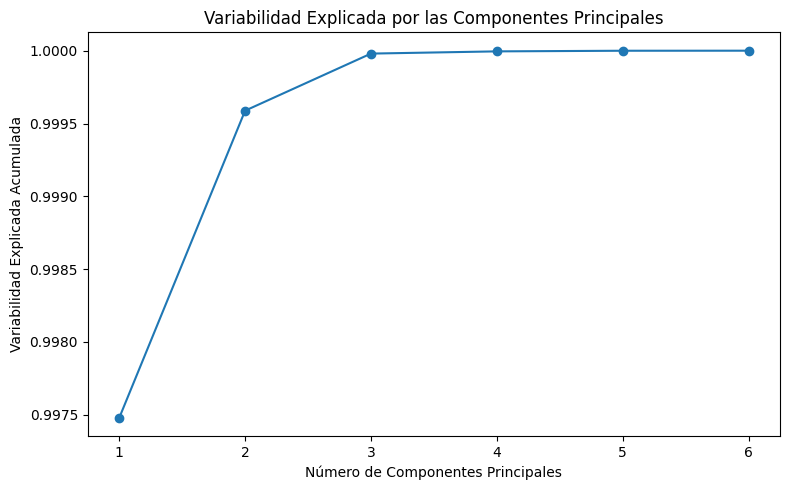

In [18]:
# Lista para almacenar los valores de MSE
mses = []
# Lista para almacenar la varianza explicada acumulada
variabilidad_acumulada = []

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Número máximo de componentes principales a considerar
n_components_max = len(predictors)
for n in range(1, n_components_max + 1):
    # Aplicar PCA con n componentes
    pca = PCA(n_components=n)
    X_pca = pca.fit_transform(X_train)

    # Varianza explicada acumulada
    variabilidad_acumulada.append(np.sum(pca.explained_variance_ratio_))


# Crear gráficos
plt.figure(figsize=(8, 5))

plt.plot(range(1, n_components_max + 1), variabilidad_acumulada, marker='o')
plt.title('Variabilidad Explicada por las Componentes Principales')
plt.xlabel('Número de Componentes Principales')
plt.ylabel('Variabilidad Explicada Acumulada')

plt.tight_layout()
plt.show()

De este modo, ya disponemos de un criterio visual para elegir el número de componentes principales, similar al método del codo en el algoritmo K-Means.

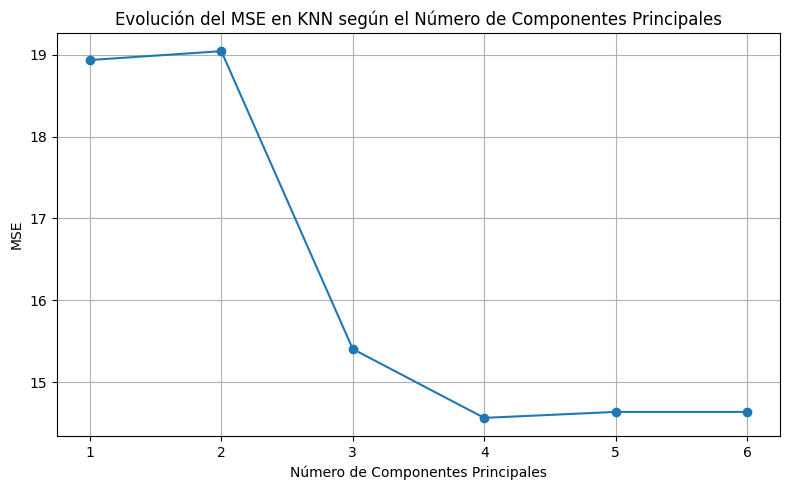

In [19]:
# Lista para almacenar los valores de MSE
mses = []

# Número máximo de componentes principales a considerar
n_components_max = len(predictors)
for n in range(1, n_components_max + 1):
    # Aplicar PCA con n componentes
    pca = PCA(n_components=n)
    X_pca = pca.fit_transform(X)

    # Dividir los datos en conjuntos de entrenamiento y prueba
    X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=0)

    # Entrenar un modelo KNN con 4 primeros vecinos
    knn = KNeighborsRegressor(n_neighbors=4)
    knn.fit(X_train, y_train)
    

    # Predecir y evaluar el modelo
    y_pred = knn.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    mses.append(mse)

# Crear gráficos
plt.figure(figsize=(8, 5))


# Gráfico de MSE
plt.plot(range(1, n_components_max + 1), mses, marker='o')
plt.title('Evolución del MSE en KNN según el Número de Componentes Principales')
plt.xlabel('Número de Componentes Principales')
plt.ylabel('MSE')

plt.grid(True)
plt.tight_layout()
plt.show()


Ahora vemos cómo evoluciona la precisión del modelo con el número de componentes principales

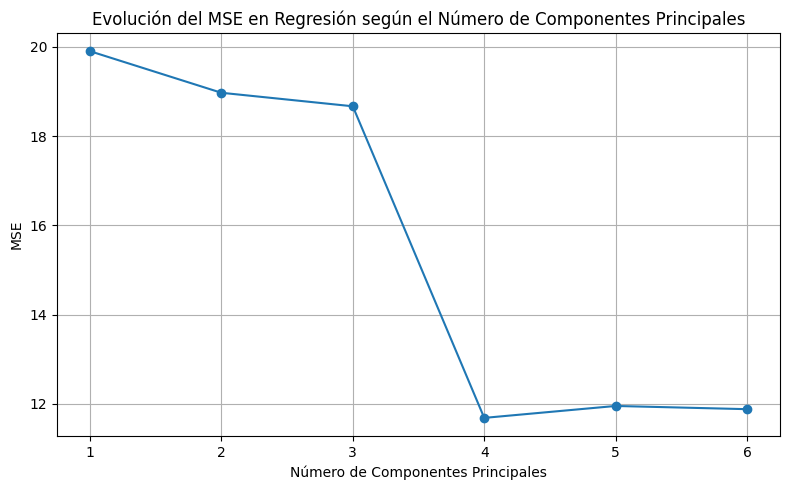

In [20]:
from sklearn.linear_model import LinearRegression

# Lista para almacenar los valores de MSE
mses = []

# Número máximo de componentes principales a considerar
n_components_max = len(predictors)
for n in range(1, n_components_max + 1):

    # Aplicar PCA con n componentes
    pca = PCA(n_components=n)
    X_pca = pca.fit_transform(X)

    # Dividir los datos en conjuntos de entrenamiento y prueba
    X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=0)

    # Entrenar un modelo de regresión
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predecir y evaluar el modelo
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    mses.append(mse)

# Crear gráficos
plt.figure(figsize=(8, 5))


# Gráfico de MSE
plt.plot(range(1, n_components_max + 1), mses, marker='o')
plt.title('Evolución del MSE en Regresión según el Número de Componentes Principales')
plt.xlabel('Número de Componentes Principales')
plt.ylabel('MSE')

plt.grid(True)
plt.tight_layout()
plt.show()


## Estandarización de los datos

El escalado estándar, también conocido como estandarización, es una técnica utilizada para normalizar la distribución de las características de un conjunto de datos. En esta técnica, ajustamos la distribución de cada atributo para que tenga una media de cero y una desviación estándar de uno.

La fórmula para el escalado estándar de un valor $ x $ en una característica es:

$$ z = \frac{(x - \mu)}{\sigma} $$

donde:
- $ z $ es el valor escalado.
- $ x $ es el valor original.
- $ \mu $ es la media de la característica.
- $ \sigma $ es la desviación estándar de la característica.

Para una característica o variable dada, la estandarización se realiza restando la media de la característica de cada valor, y luego dividiendo el resultado por la desviación estándar de la característica. Este proceso se repite para cada característica en el conjunto de datos.

El resultado es que cada variable o característica se centra en cero (debido a la sustracción de la media) y tiene unidades en términos de desviación estándar.

In [22]:
from sklearn.preprocessing import StandardScaler


Comprobemos primero de manera gráfica el resultado de la estandarización


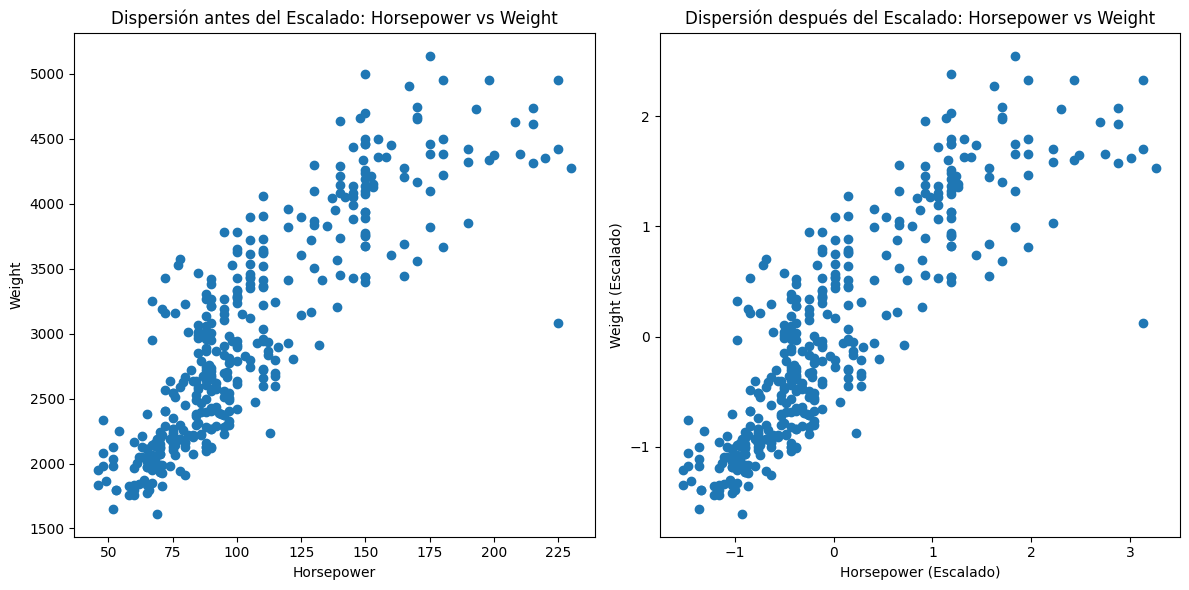

In [24]:
# Estandarizamos los datos (devuelve un array de numpy)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(X)

# Creamos un dataframe de pandas
X_scaled = pd.DataFrame(scaled_data, columns=predictors)


# Suponiendo que 'X' es tu DataFrame original y ya está definido

# Gráfico con los datos originales
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.scatter(X['Horsepower'], X['Weight'])
plt.xlabel('Horsepower')
plt.ylabel('Weight')
plt.title('Dispersión antes del Escalado: Horsepower vs Weight')

# Aplicar el escalado estándar
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=predictors)

# Gráfico con los datos escalados
plt.subplot(1, 2, 2)
plt.scatter(X_scaled['Horsepower'], X_scaled['Weight'])
plt.xlabel('Horsepower (Escalado)')
plt.ylabel('Weight (Escalado)')
plt.title('Dispersión después del Escalado: Horsepower vs Weight')

plt.tight_layout()
plt.show()


### Estandarización + PCA + KNN

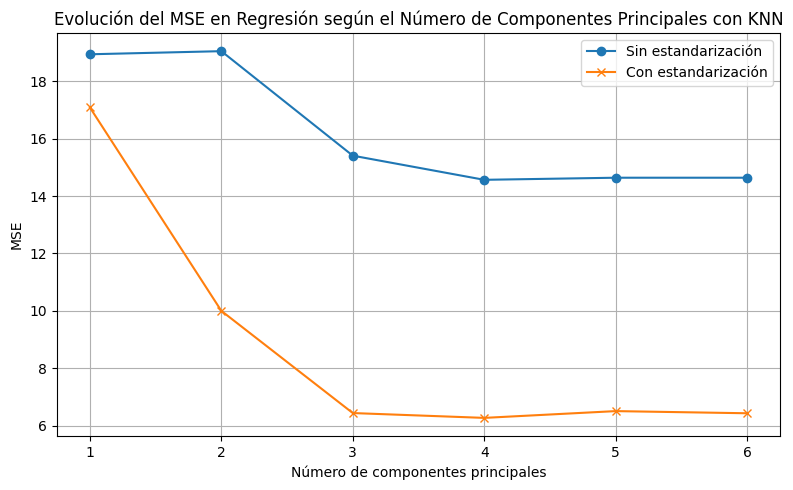

In [25]:
# Calcular el MSE para diferentes números de componentes principales
mse_no_scaling = []
mse_scaling = []
for n in range(1, n_components_max + 1):

    ### PRIMERO APLICAMOS PCA SIN ESTANDARIZAR ###
    # Aplicar PCA con n componentes
    pca = PCA(n_components=n)
    X_pca = pca.fit_transform(X)

    # Dividir los datos en conjuntos de entrenamiento y prueba
    X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=0)

    # Entrenar un modelo KNN
    knn = KNeighborsRegressor(n_neighbors=4)
    knn.fit(X_train, y_train)

    # Predecir y evaluar el modelo
    y_pred = knn.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    mse_no_scaling.append(mse)


    ### DESPUÉS ESTANDARIZAMOS ANTES DE APLICAR PCA ###
    # Estandarizamos los datos
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Aplicar PCA con n componentes
    pca = PCA(n_components=n)
    X_pca_scaled = pca.fit_transform(X_scaled)

    # Dividir los datos en conjuntos de entrenamiento y prueba
    X_train_scaled, X_test_scaled, y_train, y_test = train_test_split(X_pca_scaled, y, test_size=0.2, random_state=0)

    # Entrenar un modelo KNN con datos estandarizados
    knn = KNeighborsRegressor(n_neighbors=4)
    knn.fit(X_train_scaled, y_train)

     # Predecir y evaluar el modelo
    y_pred = knn.predict(X_test_scaled)
    mse = mean_squared_error(y_test, y_pred)
    mse_scaling.append(mse)



# Crear gráficos
plt.figure(figsize=(8, 5))

plt.plot(range(1, n_components_max + 1), mse_no_scaling, marker='o', label="Sin estandarización")
plt.plot(range(1, n_components_max + 1), mse_scaling,marker='x', label="Con estandarización")
plt.xlabel("Número de componentes principales")
plt.ylabel("MSE")

plt.title('Evolución del MSE en Regresión según el Número de Componentes Principales con KNN')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Estandarización + KNN (Sin PCA)

El mismo proceso que veíamos en ejercicios anteriores, pero aplicando estandarización.

In [26]:
from itertools import combinations

# Diccionario para almacenar los MSE medios
mse_medios_knn = {}
mse_medios_knn_scaled = {}

for num_vars in range(1, len(predictors) + 1):
    combinaciones = list(combinations(predictors, num_vars))
    mse_total = 0
    mse_total_scaled = 0

    for seed in range(5):
        # División de los datos
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

        # Estandarización de los datos
        scaler = StandardScaler()
        scaled_data = scaler.fit_transform(X)
        X_scaled = pd.DataFrame(scaled_data, columns=predictors)
        X_train_scaled, X_test_scaled, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=seed)

        for combinacion in combinaciones:
            # Subconjunto de variables para el modelo sin escalar
            X_train_comb = X_train[list(combinacion)]
            X_test_comb = X_test[list(combinacion)]

            # Entrenamiento y evaluación del modelo KNN sin escalar
            model = KNeighborsRegressor(n_neighbors=4)
            model.fit(X_train_comb, y_train)
            y_pred = model.predict(X_test_comb)
            mse = mean_squared_error(y_test, y_pred)
            mse_total += mse

            # Subconjunto de variables para el modelo escalado
            X_train_scaled_comb = X_train_scaled[list(combinacion)]
            X_test_scaled_comb = X_test_scaled[list(combinacion)]

            # Entrenamiento y evaluación del modelo KNN escalado
            model.fit(X_train_scaled_comb, y_train)
            y_pred = model.predict(X_test_scaled_comb)
            mse_scaled = mean_squared_error(y_test, y_pred)
            mse_total_scaled += mse_scaled

    # Calcular y almacenar el MSE medio
    mse_medio = mse_total / (len(combinaciones) * 5)
    mse_medios_knn[num_vars] = mse_medio
    # print(f"MSE medio con KNN (k=4) y {num_vars} variables predictoras: {mse_medio}")

    mse_medio_scaled = mse_total_scaled / (len(combinaciones) * 5)
    mse_medios_knn_scaled[num_vars] = mse_medio_scaled
    # print(f"MSE medio con KNN (k=4) y {num_vars} variables predictoras (escalado): {mse_medio_scaled}")


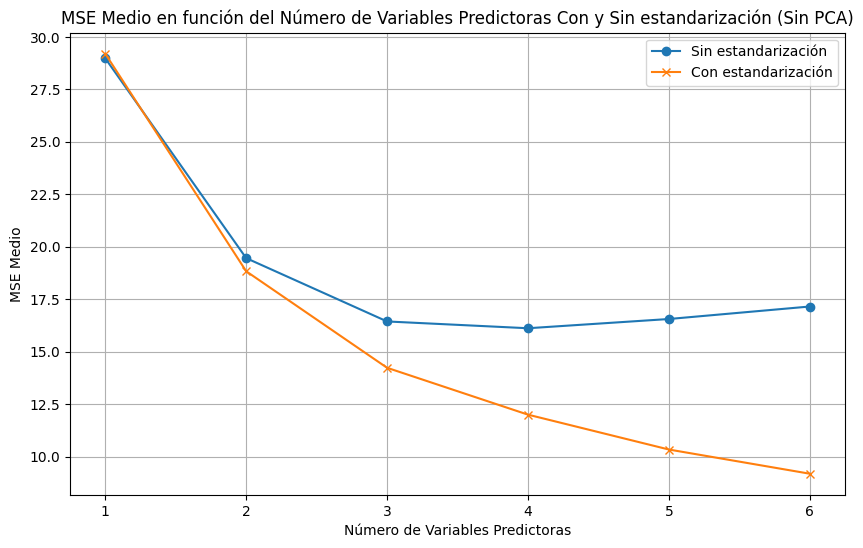

In [27]:
# Representación Gráfica

# Listas para almacenar los valores de MSE medio
mse_medios = list(mse_medios_knn.values())
mse_medios_scaled = list(mse_medios_knn_scaled.values())
num_variables = list(range(1, len(predictors) + 1))

# Creando el gráfico
plt.figure(figsize=(10, 6))

plt.plot(num_variables, mse_medios, label="Sin estandarización", marker='o')
plt.plot(num_variables, mse_medios_scaled, label="Con estandarización", marker='x')

plt.title('MSE Medio en función del Número de Variables Predictoras Con y Sin estandarización (Sin PCA)')
plt.xlabel('Número de Variables Predictoras')
plt.ylabel('MSE Medio')
plt.xticks(num_variables)
plt.legend()
plt.grid(True)
plt.show()


### Estandarización + PCA + Regresión

In [28]:
# Calcular el MSE para diferentes números de componentes principales
mse_no_scaling = []
mse_scaling = []
for n in range(1, n_components_max + 1):

    ### PRIMERO APLICAMOS PCA SIN ESTANDARIZAR ###
    # Aplicar PCA con n componentes
    pca =   PCA(n_components=n)
    X_pca = pca.fit_transform(X)

    # Dividir los datos en conjuntos de entrenamiento y prueba
    X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=0)

    # Entrenar un modelo de regresión
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predecir y evaluar el modelo
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    mse_no_scaling.append(mse)


    ### DESPUÉS ESTANDARIZAMOS ANTES DE APLICAR PCA ###
    # Estandarizamos los datos
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Aplicar PCA con n componentes
    pca = PCA(n_components=n)
    X_pca_scaled = pca.fit_transform(X_scaled)

    # Dividir los datos en conjuntos de entrenamiento y prueba
    X_train_scaled, X_test_scaled, y_train, y_test = train_test_split(X_pca_scaled, y, test_size=0.2, random_state=0)


    # Entrenar un modelo de regresión con datos estandarizados
    model = LinearRegression()
    model.fit(X_train_scaled, y_train)

     # Predecir y evaluar el modelo
    y_pred = model.predict(X_test_scaled)
    mse = mean_squared_error(y_test, y_pred)
    mse_scaling.append(mse)

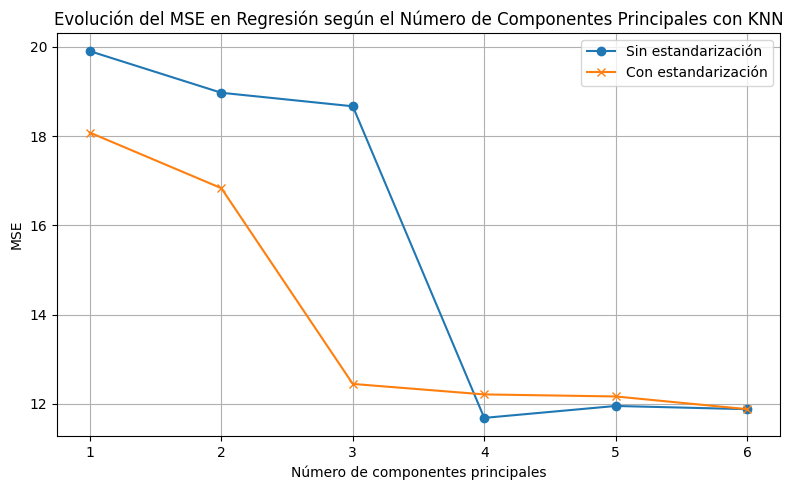

In [29]:
# Crear gráficos
plt.figure(figsize=(8, 5))

plt.plot(range(1, n_components_max + 1), mse_no_scaling, marker='o', label="Sin estandarización")
plt.plot(range(1, n_components_max + 1), mse_scaling,marker='x', label="Con estandarización")
plt.xlabel("Número de componentes principales")
plt.ylabel("MSE")

plt.title('Evolución del MSE en Regresión según el Número de Componentes Principales con KNN')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()